# Module 8: Deep Learning Basics: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-08-deep-learning/Module_8_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. ▶️ [Module 8 videos](https://www.youtube.com/playlist?list=PLKeCiuH5RiLc) · 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/41e6f1ed006e81989a20f0e1404dcdcf) · 💻 [Module 8 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-08-deep-learning)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## neural_network_lesson.py

Module 8: Deep Learning & Neural Networks: Practical Lesson
Scenario: Reading handwritten digits with a neural network

The dataset is scikit-learn's handwritten digits: 1,797 small greyscale images
(8 x 8 pixels) of the digits 0 to 9. It ships with scikit-learn, so there is
nothing to download.

The lab has four parts:

  Part 0  Activation functions: sigmoid, tanh, ReLU and leaky ReLU, their
          derivatives, and why stacking linear layers without them is
          pointless.
  Part 1  A neural network built from scratch in NumPy: forward pass,
          softmax, cross-entropy loss, backpropagation by hand and gradient
          descent. A gradient check proves the backprop maths is right.
  Part 2  The same experiment with three hidden-layer activations (sigmoid,
          tanh, ReLU) to see which one learns fastest.
  Part 3  The same network in Keras (with Adam, dropout and early stopping),
          plus a small convolutional network (CNN), to see what a framework
          does for you.

Run:  python neural_network_lesson.py
Needs: numpy, scikit-learn, matplotlib (Parts 0 to 2) and tensorflow (Part 3).
If TensorFlow is not installed, Part 3 is skipped and everything else runs.

In [1]:
import numpy as np
import matplotlib
matplotlib.use("Agg")  # save the figure to a file; no window needed
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
SEED = 42
np.random.seed(SEED)

### `load_data()`: Load the digits, scale pixels to 0..1 and split into train/test.

In [2]:
# =============================================================================
# DATA
# =============================================================================
def load_data():
    """Load the digits, scale pixels to 0..1 and split into train/test."""
    print("[Data] Loading scikit-learn's handwritten digits...")
    digits = load_digits()
    X = digits.data / 16.0          # pixel values are 0..16, scale them to 0..1
    y = digits.target               # the digit, 0 to 9

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=y
    )
    print(f"  {X.shape[0]} images of {digits.images.shape[1]}x{digits.images.shape[2]} pixels "
          f"= {X.shape[1]} input features each")
    print(f"  Train: {len(X_train)} images | Test: {len(X_test)} images | Classes: 10\n")
    return X_train, X_test, y_train, y_test, digits

### `one_hot()`: Turn labels like 3 into vectors like [0,0,0,1,0,0,0,0,0,0].

In [3]:
def one_hot(y, n_classes=10):
    """Turn labels like 3 into vectors like [0,0,0,1,0,0,0,0,0,0]."""
    out = np.zeros((len(y), n_classes))
    out[np.arange(len(y)), y] = 1.0
    return out

### `sigmoid()`

In [4]:
# =============================================================================
# PART 0: ACTIVATION FUNCTIONS
# =============================================================================
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

### `sigmoid_grad()`

In [5]:
def sigmoid_grad(z):
    s = sigmoid(z)
    return s * (1.0 - s)

### `tanh()`

In [6]:
def tanh(z):
    return np.tanh(z)

### `tanh_grad()`

In [7]:
def tanh_grad(z):
    return 1.0 - np.tanh(z) ** 2

### `relu()`

In [8]:
def relu(z):
    return np.maximum(0.0, z)

### `relu_grad()`

In [9]:
def relu_grad(z):
    return (np.asarray(z) > 0).astype(float)

### `leaky_relu()`

In [10]:
def leaky_relu(z, alpha=0.01):
    return np.where(z > 0, z, alpha * z)
ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_grad),
    "tanh": (tanh, tanh_grad),
    "relu": (relu, relu_grad),
}

### `part0_activations()`

In [11]:
def part0_activations():
    print("=" * 70)
    print("PART 0: ACTIVATION FUNCTIONS")
    print("=" * 70)

    z = np.array([-5.0, -1.0, 0.0, 1.0, 5.0])
    print(f"{'z':>8} | {'sigmoid':>8} | {'tanh':>8} | {'ReLU':>6} | {'leaky':>7}")
    for v in z:
        print(f"{v:>8.1f} | {sigmoid(v):>8.4f} | {tanh(v):>8.4f} | {relu(v):>6.1f} | {leaky_relu(v):>7.2f}")

    # The vanishing gradient in one number: sigmoid's slope is never above 0.25
    zs = np.linspace(-10, 10, 2001)
    print(f"\nLargest slope of sigmoid: {sigmoid_grad(zs).max():.3f} (at z = 0)")
    print(f"Largest slope of tanh:    {tanh_grad(zs).max():.3f} (at z = 0)")
    print(f"Slope of sigmoid at z = 5: {sigmoid_grad(5.0):.4f}  <- almost flat: 'saturated'")
    print(f"Slope of ReLU for any z > 0: {relu_grad(5.0):.0f}  <- never saturates for positive z")
    print("Through 10 sigmoid layers the gradient shrinks by at least "
          f"0.25^10 = {0.25 ** 10:.1e}. That is the vanishing gradient problem.")

    # Why non-linearity matters: two linear layers collapse into one
    rng = np.random.default_rng(SEED)
    x = rng.normal(size=(5, 4))
    W1, b1 = rng.normal(size=(4, 3)), rng.normal(size=3)
    W2, b2 = rng.normal(size=(3, 2)), rng.normal(size=2)
    two_layers = (x @ W1 + b1) @ W2 + b2
    W_net, b_net = W1 @ W2, b1 @ W2 + b2          # one equivalent layer
    one_layer = x @ W_net + b_net
    print("\nTwo stacked linear layers vs one combined linear layer, max difference: "
          f"{np.abs(two_layers - one_layer).max():.1e}")
    print("They are the same function. Without a non-linear activation, depth adds nothing.\n")

### `NumpyMLP()`: A fully connected network: 64 inputs -> hidden layer -> 10 outputs.

In [12]:
# =============================================================================
# PART 1: A NEURAL NETWORK FROM SCRATCH (NumPy)
# =============================================================================
class NumpyMLP:
    """
    A fully connected network: 64 inputs -> hidden layer -> 10 outputs.

    Forward pass
        z1 = X W1 + b1          (weighted sum for each hidden neuron)
        a1 = g(z1)              (activation: ReLU, tanh or sigmoid)
        z2 = a1 W2 + b2         (one score per digit)
        p  = softmax(z2)        (scores -> probabilities that add up to 1)
    Loss
        cross-entropy: L = -mean( log p[true class] )
    Backward pass (chain rule, from the output back to the input)
        dz2 = (p - Y) / n                   (softmax + cross-entropy combined)
        dW2 = a1^T dz2,  db2 = sum(dz2)
        da1 = dz2 W2^T
        dz1 = da1 * g'(z1)
        dW1 = X^T dz1,   db1 = sum(dz1)
    Update (gradient descent)
        W = W - learning_rate * dW
    """

    def __init__(self, n_in=64, n_hidden=32, n_out=10, activation="relu", seed=SEED):
        rng = np.random.default_rng(seed)
        # He initialisation for ReLU, Xavier for sigmoid/tanh: keeps signals a sensible size
        scale = np.sqrt(2.0 / n_in) if activation == "relu" else np.sqrt(1.0 / n_in)
        self.W1 = rng.normal(0, scale, size=(n_in, n_hidden))
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.normal(0, np.sqrt(1.0 / n_hidden), size=(n_hidden, n_out))
        self.b2 = np.zeros(n_out)
        self.g, self.g_grad = ACTIVATIONS[activation]
        self.activation = activation

    @staticmethod
    def softmax(z):
        z = z - z.max(axis=1, keepdims=True)   # subtract the max for numerical stability
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def forward(self, X):
        self.X = X
        self.z1 = X @ self.W1 + self.b1
        self.a1 = self.g(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.p = self.softmax(self.z2)
        return self.p

    @staticmethod
    def loss(p, Y):
        return -np.mean(np.sum(Y * np.log(p + 1e-12), axis=1))

    def backward(self, Y):
        n = Y.shape[0]
        dz2 = (self.p - Y) / n
        grads = {"W2": self.a1.T @ dz2, "b2": dz2.sum(axis=0)}
        da1 = dz2 @ self.W2.T
        dz1 = da1 * self.g_grad(self.z1)
        grads["W1"] = self.X.T @ dz1
        grads["b1"] = dz1.sum(axis=0)
        return grads

    def step(self, grads, lr):
        for name, grad in grads.items():
            setattr(self, name, getattr(self, name) - lr * grad)

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

    def fit(self, X, y, epochs=40, lr=0.5, batch_size=32, verbose=True):
        Y = one_hot(y)
        rng = np.random.default_rng(SEED)
        history = []
        for epoch in range(1, epochs + 1):
            order = rng.permutation(len(X))           # shuffle every epoch
            for start in range(0, len(X), batch_size):
                idx = order[start:start + batch_size]
                self.forward(X[idx])
                self.step(self.backward(Y[idx]), lr)
            epoch_loss = self.loss(self.forward(X), Y)
            history.append(epoch_loss)
            if verbose and (epoch == 1 or epoch % 10 == 0):
                acc = (self.predict(X) == y).mean()
                print(f"  Epoch {epoch:>3} | loss {epoch_loss:.4f} | train accuracy {acc:.1%}")
        return history

### `gradient_check()`: Compare backprop gradients with slow numerical ones: they should match.

In [13]:
def gradient_check(X, y):
    """Compare backprop gradients with slow numerical ones: they should match."""
    net = NumpyMLP(activation="tanh")
    Xb, Yb = X[:10], one_hot(y[:10])
    net.forward(Xb)
    grads = net.backward(Yb)

    eps, worst = 1e-5, 0.0
    rng = np.random.default_rng(0)
    for name in ["W1", "b1", "W2", "b2"]:
        param = getattr(net, name)
        for _ in range(5):                                  # check 5 random entries per parameter
            i = tuple(rng.integers(0, s) for s in param.shape)
            old = param[i]
            param[i] = old + eps; plus = net.loss(net.forward(Xb), Yb)
            param[i] = old - eps; minus = net.loss(net.forward(Xb), Yb)
            param[i] = old
            numeric = (plus - minus) / (2 * eps)
            rel = abs(numeric - grads[name][i]) / max(1e-8, abs(numeric) + abs(grads[name][i]))
            worst = max(worst, rel)
    return worst

### `part1_numpy()`

In [14]:
def part1_numpy(X_train, X_test, y_train, y_test):
    print("=" * 70)
    print("PART 1: A NEURAL NETWORK FROM SCRATCH (NumPy)")
    print("=" * 70)
    print("Architecture: 64 inputs -> 32 hidden (ReLU) -> 10 outputs (softmax)")
    n_params = 64 * 32 + 32 + 32 * 10 + 10
    print(f"Parameters to learn: {n_params:,} weights and biases")

    worst = gradient_check(X_train, y_train)
    print(f"Gradient check: worst relative error {worst:.1e} "
          f"({'PASS' if worst < 1e-6 else 'FAIL'}: backprop matches the numerical slope)\n")

    print("Majority-class baseline (always guess the most common digit): "
          f"{(y_test == np.bincount(y_train).argmax()).mean():.1%}")
    print("Training with mini-batch gradient descent (batch 32, learning rate 0.5):")
    net = NumpyMLP(activation="relu")
    history = net.fit(X_train, y_train, epochs=40, lr=0.5)
    test_acc = (net.predict(X_test) == y_test).mean()
    print(f"\nNumPy network test accuracy: {test_acc:.1%}\n")
    return net, test_acc

### `part2_compare_activations()`

In [15]:
# =============================================================================
# PART 2: WHICH HIDDEN-LAYER ACTIVATION LEARNS FASTEST?
# =============================================================================
def part2_compare_activations(X_train, X_test, y_train, y_test, epochs=40, lr=0.1):
    print("=" * 70)
    print("PART 2: SIGMOID vs TANH vs ReLU (same network, same data)")
    print("=" * 70)
    print(f"Each network trains for {epochs} epochs with plain gradient descent, learning rate {lr}.")
    histories, results = {}, {}
    for name in ["sigmoid", "tanh", "relu"]:
        net = NumpyMLP(activation=name)
        histories[name] = net.fit(X_train, y_train, epochs=epochs, lr=lr, verbose=False)
        results[name] = (net.predict(X_test) == y_test).mean()
        print(f"  {name:<8} | loss after 5 epochs {histories[name][4]:.3f} | "
              f"final loss {histories[name][-1]:.3f} | test accuracy {results[name]:.1%}")
    print("Sigmoid is the slowest learner: its slope is at most 0.25 and it is not\n"
          "zero-centred. ReLU and tanh pass gradients back far more strongly.\n")
    return histories, results

### `part3_keras()`

In [16]:
# =============================================================================
# PART 3: THE SAME IDEAS IN KERAS
# =============================================================================
def part3_keras(X_train, X_test, y_train, y_test):
    print("=" * 70)
    print("PART 3: KERAS (TensorFlow)")
    print("=" * 70)
    try:
        import os
        os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow's start-up logs
        import tensorflow as tf
        from tensorflow import keras
    except ImportError:
        print("TensorFlow is not installed, so Part 3 is skipped.")
        print("Install it with:  pip install tensorflow\n")
        return None

    keras.utils.set_random_seed(SEED)

    # --- 3a. Dense network: same shape as Part 1, plus Adam, dropout and early stopping
    dense = keras.Sequential([
        keras.Input(shape=(64,)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.2),                       # switch off 20% of neurons while training
        keras.layers.Dense(10, activation="softmax"),
    ])
    dense.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    print("Model 1: Dense network (Sequential API)")
    dense.summary(print_fn=lambda line: print("  " + line) if line.strip() else None)

    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                               restore_best_weights=True)
    hist = dense.fit(X_train, y_train, validation_split=0.2, epochs=200, batch_size=32,
                     callbacks=[early_stop], verbose=0)
    stopped = len(hist.history["loss"])
    _, dense_acc = dense.evaluate(X_test, y_test, verbose=0)
    print(f"  Early stopping ended training after {stopped} of 200 epochs "
          f"(best validation loss at epoch {int(np.argmin(hist.history['val_loss'])) + 1}).")
    print(f"  Dense network test accuracy: {dense_acc:.1%}\n")

    # --- 3b. A small CNN: treat each sample as an 8x8 image instead of 64 loose numbers
    X_train_img, X_test_img = X_train.reshape(-1, 8, 8, 1), X_test.reshape(-1, 8, 8, 1)
    cnn = keras.Sequential([
        keras.Input(shape=(8, 8, 1)),
        keras.layers.Conv2D(16, kernel_size=3, activation="relu", padding="same"),
        keras.layers.MaxPooling2D(pool_size=2),          # 8x8 -> 4x4
        keras.layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation="softmax"),
    ])
    cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cnn_hist = cnn.fit(X_train_img, y_train, validation_split=0.2, epochs=200, batch_size=32,
                       callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                                restore_best_weights=True)],
                       verbose=0)
    _, cnn_acc = cnn.evaluate(X_test_img, y_test, verbose=0)
    print("Model 2: Small CNN (Conv2D -> MaxPooling2D -> Conv2D -> Dense)")
    print(f"  Parameters: {cnn.count_params():,} | trained for {len(cnn_hist.history['loss'])} epochs")
    print(f"  CNN test accuracy: {cnn_acc:.1%}\n")

    preds = cnn.predict(X_test_img, verbose=0).argmax(axis=1)
    return {"history": hist.history, "dense_acc": dense_acc, "cnn_acc": cnn_acc,
            "cnn_preds": preds}

### `plot_all()`

In [17]:
# =============================================================================
# PLOT
# =============================================================================
def plot_all(histories, keras_out, X_test, y_test, numpy_net):
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))

    # A) Activation functions
    z = np.linspace(-5, 5, 400)
    ax = axes[0, 0]
    ax.plot(z, sigmoid(z), label="Sigmoid  (0, 1)", linewidth=2.5)
    ax.plot(z, tanh(z), label="Tanh  (-1, 1)", linewidth=2.5)
    ax.plot(z, relu(z), label="ReLU  [0, ∞)", linewidth=2.5)
    ax.plot(z, leaky_relu(z, 0.1), "--", label="Leaky ReLU (α = 0.1 for visibility)", linewidth=1.8)
    ax.axhline(0, color="grey", linewidth=0.8); ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_ylim(-1.5, 3); ax.set_title("A) Activation functions", fontsize=14, fontweight="bold")
    ax.set_xlabel("z (weighted sum + bias)"); ax.set_ylabel("g(z)"); ax.legend(loc="upper left")

    # B) Training loss by activation (from Part 2)
    ax = axes[0, 1]
    for name, h in histories.items():
        ax.plot(range(1, len(h) + 1), h, label=name, linewidth=2.5)
    ax.set_title("B) Training loss: sigmoid vs tanh vs ReLU", fontsize=14, fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.legend()

    # C) Keras training vs validation accuracy (or NumPy fallback message)
    ax = axes[1, 0]
    if keras_out is not None:
        h = keras_out["history"]
        epochs = range(1, len(h["accuracy"]) + 1)
        ax.plot(epochs, h["accuracy"], label="Training accuracy (with dropout on)", linewidth=2.5)
        ax.plot(epochs, h["val_accuracy"], label="Validation accuracy", linewidth=2.5)
        best = int(np.argmin(h["val_loss"])) + 1
        ax.axvline(best, color="#d62728", linestyle="--", label=f"Best epoch kept ({best})")
        ax.set_title("C) Keras dense network with early stopping", fontsize=14, fontweight="bold")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.legend(loc="lower right")
    else:
        ax.text(0.5, 0.5, "Install TensorFlow to see\nthe Keras training curves",
                ha="center", va="center", fontsize=14)
        ax.set_axis_off()

    # D) Sample predictions
    ax = axes[1, 1]
    ax.set_axis_off()
    ax.set_title("D) Test images with predictions", fontsize=14, fontweight="bold")
    preds = keras_out["cnn_preds"] if keras_out is not None else numpy_net.predict(X_test)
    wrong = np.where(preds != y_test)[0]
    right = np.where(preds == y_test)[0]
    show = list(right[:12]) + list(wrong[:4])          # mostly right, a few mistakes
    for k, i in enumerate(show[:16]):
        sub = ax.inset_axes([(k % 4) * 0.25 + 0.03, 0.76 - (k // 4) * 0.25, 0.19, 0.19])
        sub.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
        ok = preds[i] == y_test[i]
        sub.set_title(f"pred {preds[i]}" + ("" if ok else f" (true {y_test[i]})"),
                      fontsize=9, color="#2ca02c" if ok else "#d62728")
        sub.set_xticks([]); sub.set_yticks([])

    plt.tight_layout()
    path = "deep_learning_master_plot.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"[Plot] Saved {path}")

### `main()`

In [18]:
# =============================================================================
def main():
    print("=" * 70)
    print("MODULE 8: DEEP LEARNING & NEURAL NETWORKS: PRACTICAL LAB")
    print("=" * 70 + "\n")
    X_train, X_test, y_train, y_test, _ = load_data()

    part0_activations()
    numpy_net, numpy_acc = part1_numpy(X_train, X_test, y_train, y_test)
    histories, act_results = part2_compare_activations(X_train, X_test, y_train, y_test)
    keras_out = part3_keras(X_train, X_test, y_train, y_test)

    print("=" * 70)
    print("SUMMARY (test accuracy on 360 unseen images)")
    print("=" * 70)
    print(f"  NumPy network, ReLU, built by hand ........ {numpy_acc:.1%}")
    for name, acc in act_results.items():
        print(f"  NumPy, {name:<7} (Part 2, lr 0.1, 40 epochs) .. {acc:.1%}")
    if keras_out is not None:
        print(f"  Keras dense network (Adam + dropout) ....... {keras_out['dense_acc']:.1%}")
        print(f"  Keras small CNN ............................ {keras_out['cnn_acc']:.1%}")
    print()
    plot_all(histories, keras_out, X_test, y_test, numpy_net)

### Run the lab

In [19]:
main()

MODULE 8: DEEP LEARNING & NEURAL NETWORKS: PRACTICAL LAB

[Data] Loading scikit-learn's handwritten digits...
  1797 images of 8x8 pixels = 64 input features each
  Train: 1437 images | Test: 360 images | Classes: 10

PART 0: ACTIVATION FUNCTIONS
       z |  sigmoid |     tanh |   ReLU |   leaky
    -5.0 |   0.0067 |  -0.9999 |    0.0 |   -0.05
    -1.0 |   0.2689 |  -0.7616 |    0.0 |   -0.01
     0.0 |   0.5000 |   0.0000 |    0.0 |    0.00
     1.0 |   0.7311 |   0.7616 |    1.0 |    1.00
     5.0 |   0.9933 |   0.9999 |    5.0 |    5.00

Largest slope of sigmoid: 0.250 (at z = 0)
Largest slope of tanh:    1.000 (at z = 0)
Slope of sigmoid at z = 5: 0.0066  <- almost flat: 'saturated'
Slope of ReLU for any z > 0: 1  <- never saturates for positive z
Through 10 sigmoid layers the gradient shrinks by at least 0.25^10 = 9.5e-07. That is the vanishing gradient problem.

Two stacked linear layers vs one combined linear layer, max difference: 4.4e-16
They are the same function. Without a 

### Show `deep_learning_master_plot.png`

The script saves its chart to a file. This cell displays it.

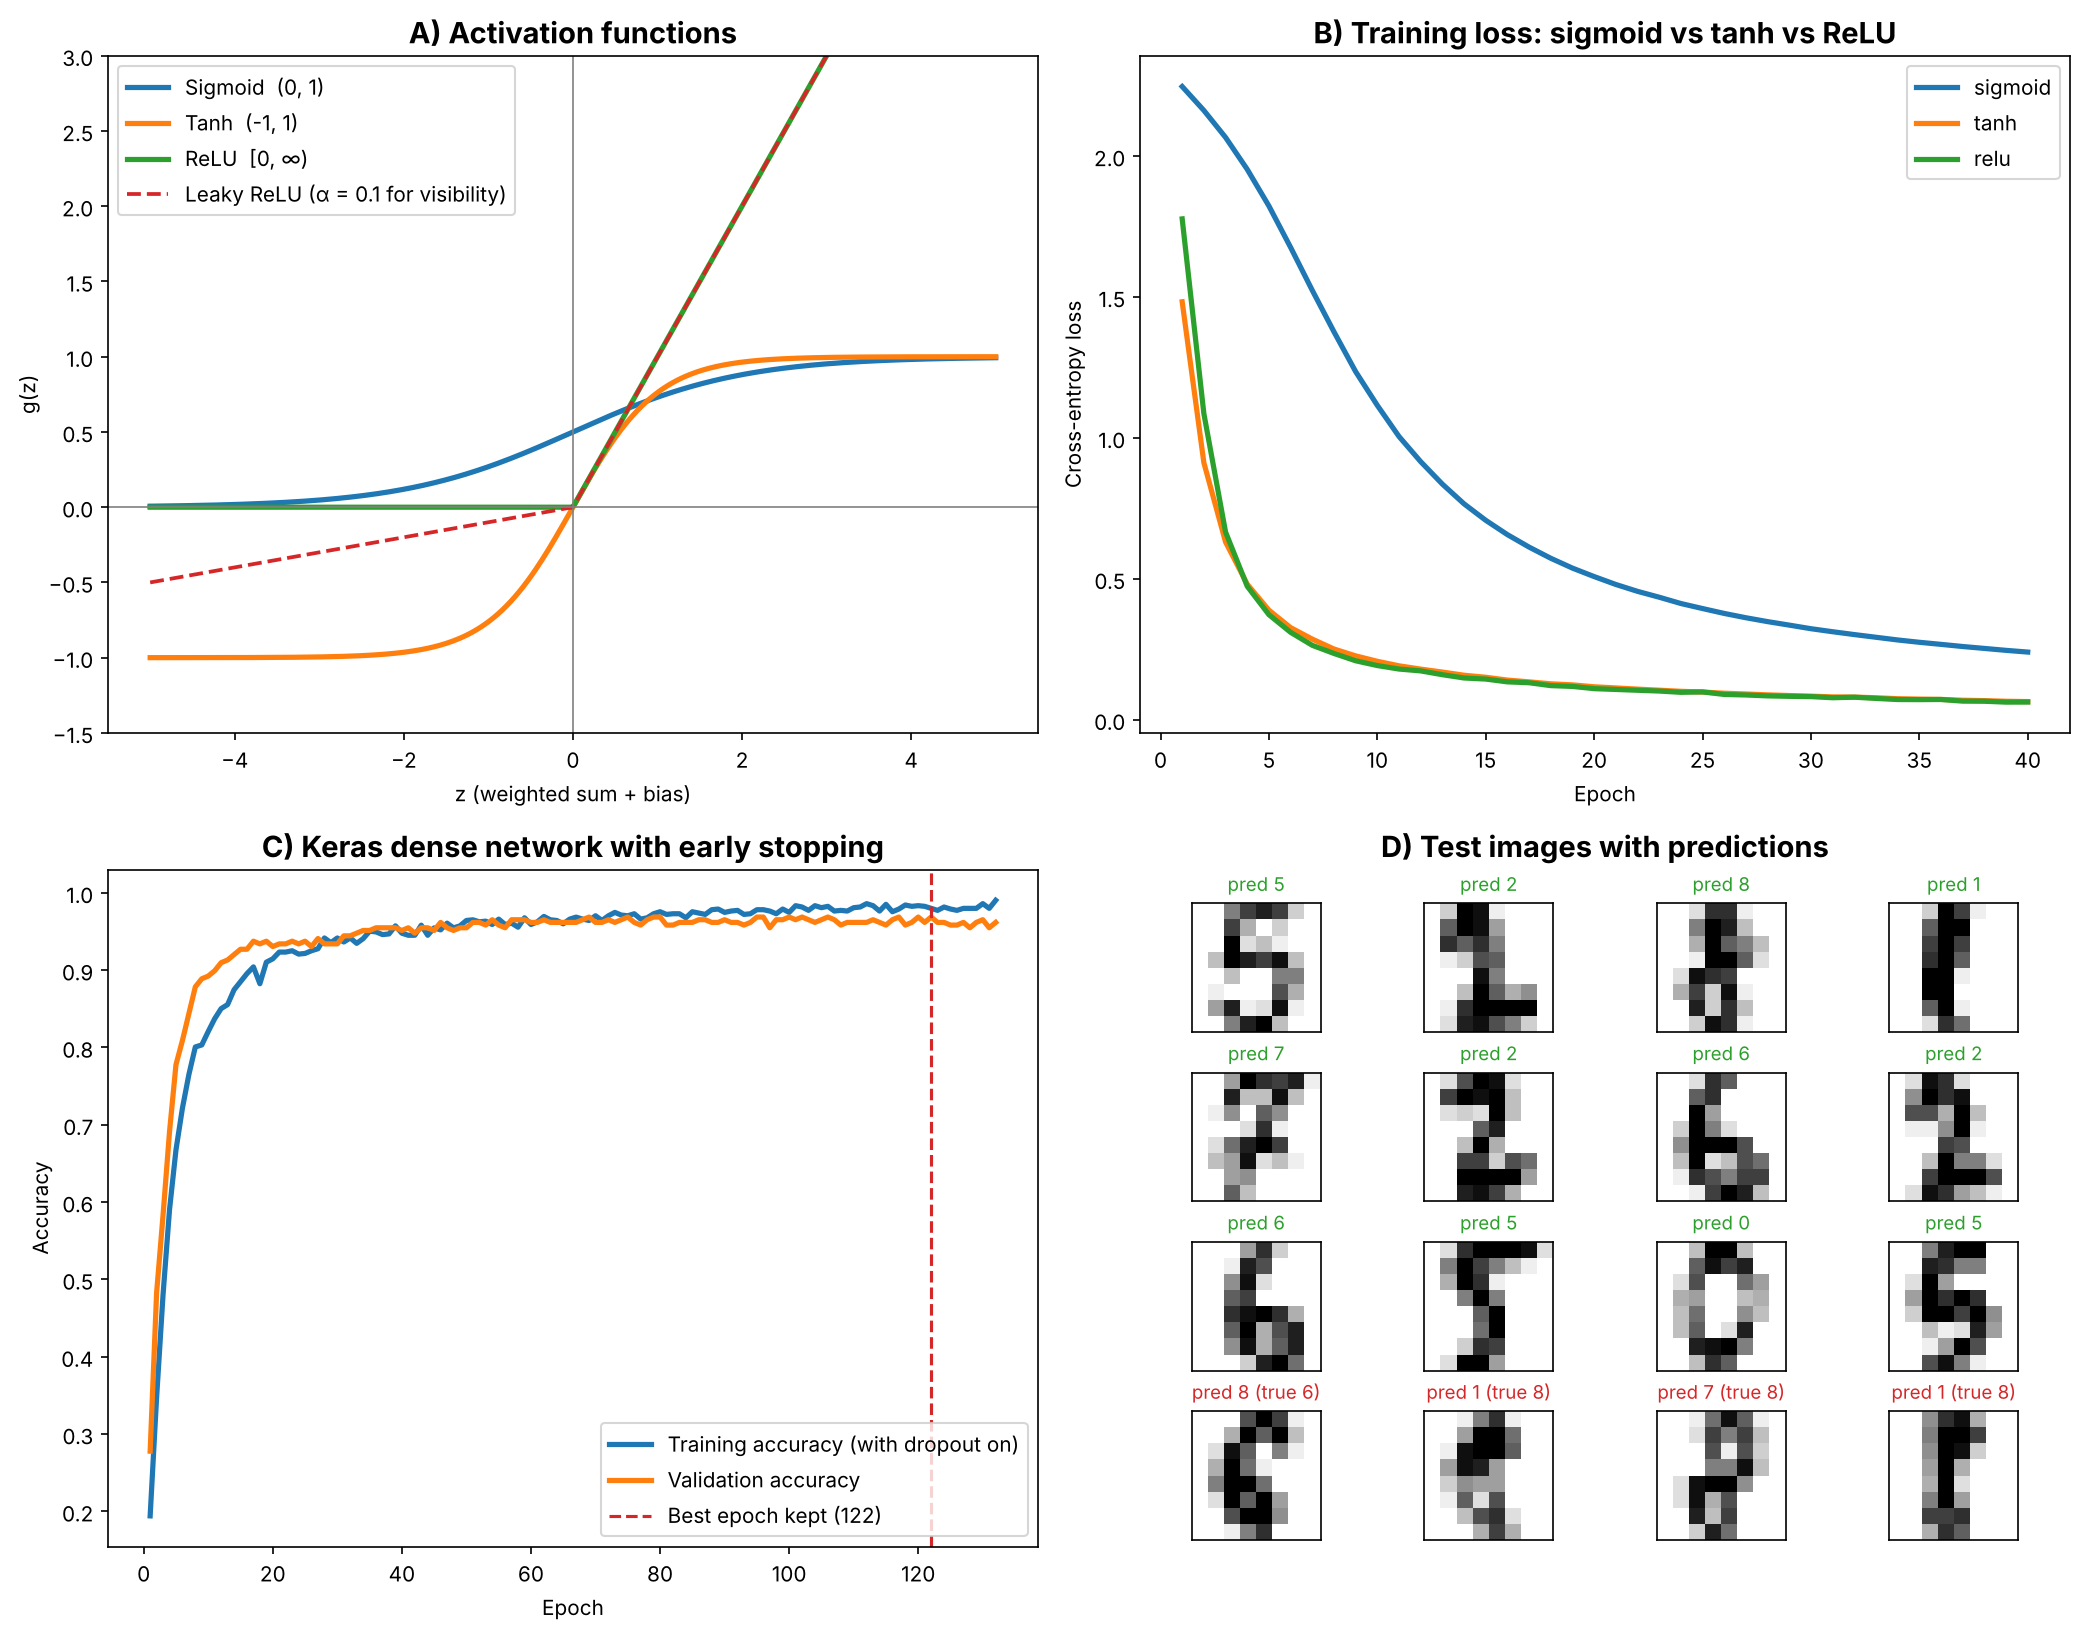

In [20]:
from IPython.display import Image, display
display(Image("deep_learning_master_plot.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)